In [1]:
#Excercise 2
#Step-1

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [3]:
device='cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
w=0.3
b=0.9

In [5]:
x=torch.arange(start=0,end=1,step=0.02).unsqueeze(dim=1)

In [6]:
train_split=int(0.8*len(x))

In [7]:
x_train=x[:train_split]
y_train=x[:train_split]

In [8]:
x_test=x[train_split:]
y_test=x[train_split:]

In [9]:
def plot_predictions(train_data=x_train,train_label=y_train,test_data=x_test,test_labels=y_test,predictions=None):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_label,c="b",label="Training Data")
  plt.scatter(test_data,test_labels,c="g",label="Testing Data")
  if predictions is not None:
    plt.scatter(test_data,predictions,c='r',label='Predictions')
  plt.legend()
  plt.show()

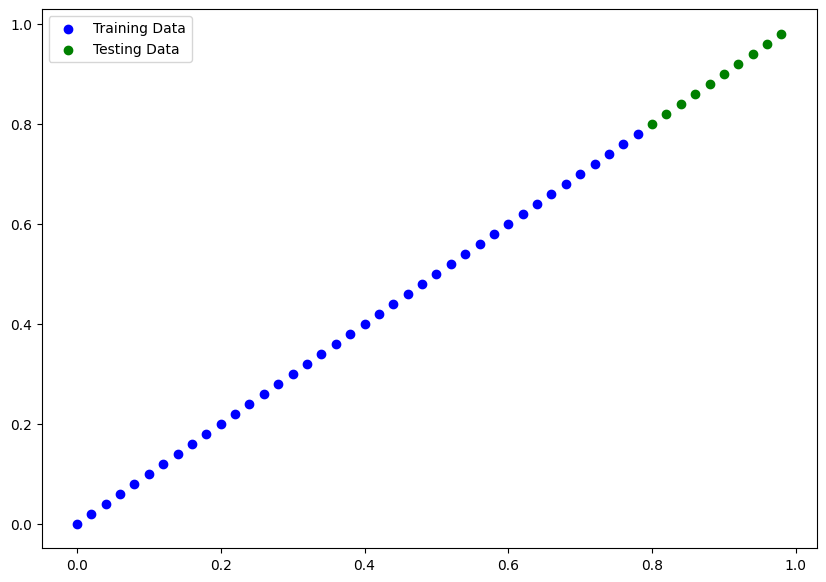

In [10]:
plot_predictions()

In [11]:
#Step-2

In [12]:
class LinearRegression_2(nn.Module):
  def __init__(self):
    super().__init__()
    self.weight=nn.Parameter(torch.randn(1,requires_grad=True,dtype=torch.float64))
    self.bias=nn.Parameter(torch.randn(1,requires_grad=True,dtype=torch.float64))
  def forward(self,x:torch.tensor)->torch.tensor:
    return self.weight*x+self.bias

In [13]:
torch.manual_seed(42)
model_0=LinearRegression_2()
model_0.state_dict()

OrderedDict([('weight', tensor([0.3367], dtype=torch.float64)),
             ('bias', tensor([0.1288], dtype=torch.float64))])

In [14]:
#Step-3

In [15]:
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [16]:
#Training and testing loop
torch.manual_seed(42)
epochs=300
for epoch in range(epochs):
  model_0.train()
  y_pred=model_0(x_train)
  loss=loss_fn(y_pred,y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_0.eval()
  with torch.inference_mode():
    test_pred=model_0(x_test)
    test_loss=loss_fn(test_pred,y_test)
  if epoch%10==0:
    print(f"Epoch:{epoch} | Loss:{loss} | Test Loss:{test_loss}")

Epoch:0 | Loss:0.1644371203013625 | Test Loss:0.45346568582000335
Epoch:10 | Loss:0.1380200884990423 | Test Loss:0.38710138615834777
Epoch:20 | Loss:0.12407913625345675 | Test Loss:0.3392970864486359
Epoch:30 | Loss:0.11643104267529716 | Test Loss:0.3055988867143847
Epoch:40 | Loss:0.1111699270204507 | Test Loss:0.2811167869460576
Epoch:50 | Loss:0.10716992720671523 | Test Loss:0.26331678716976137
Epoch:60 | Loss:0.10350940451383797 | Test Loss:0.2502627874253832
Epoch:70 | Loss:0.1000194046922048 | Test Loss:0.23924278769468438
Epoch:80 | Loss:0.09652940487057168 | Test Loss:0.22822278796398546
Epoch:90 | Loss:0.09303940504893857 | Test Loss:0.21720278823328654
Epoch:100 | Loss:0.08959400309961732 | Test Loss:0.2089303884872574
Epoch:110 | Loss:0.08616180538790714 | Test Loss:0.20065798874122823
Epoch:120 | Loss:0.08272300555739145 | Test Loss:0.19238558899519903
Epoch:130 | Loss:0.07929207354281007 | Test Loss:0.18480008924533742
Epoch:140 | Loss:0.07585820589413941 | Test Loss:0.176

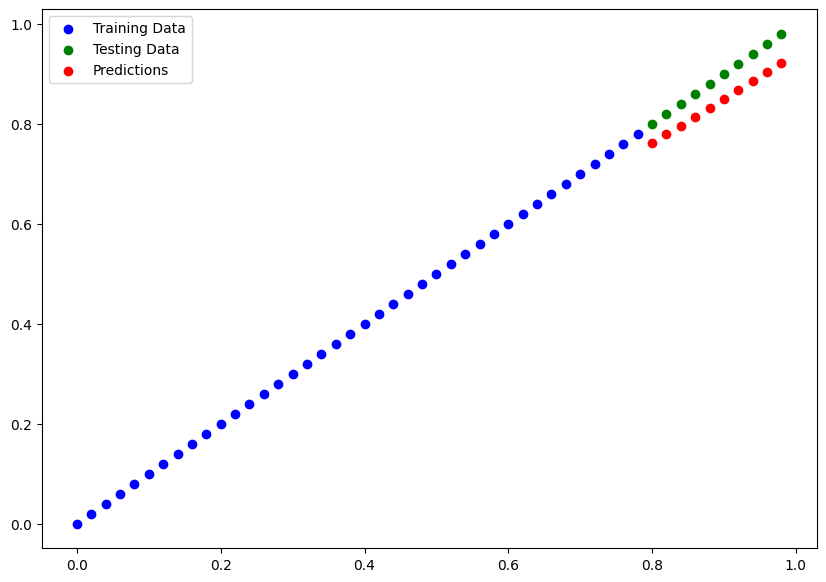

In [17]:
plot_predictions(predictions=test_pred)

In [18]:
#Step 4

In [19]:
with torch.inference_mode():
  y_pre=model_0(x_test)
y_pred

tensor([[0.0443],
        [0.0622],
        [0.0801],
        [0.0980],
        [0.1158],
        [0.1337],
        [0.1516],
        [0.1695],
        [0.1874],
        [0.2053],
        [0.2232],
        [0.2410],
        [0.2589],
        [0.2768],
        [0.2947],
        [0.3126],
        [0.3305],
        [0.3484],
        [0.3662],
        [0.3841],
        [0.4020],
        [0.4199],
        [0.4378],
        [0.4557],
        [0.4735],
        [0.4914],
        [0.5093],
        [0.5272],
        [0.5451],
        [0.5630],
        [0.5809],
        [0.5987],
        [0.6166],
        [0.6345],
        [0.6524],
        [0.6703],
        [0.6882],
        [0.7061],
        [0.7239],
        [0.7418]], dtype=torch.float64, grad_fn=<AddBackward0>)

In [20]:
#Excersice of chapter 2

In [21]:
import torch
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from torch import nn
import matplotlib.pyplot as plt

In [22]:
n_samples=1000

In [23]:
x,y=make_moons(n_samples=n_samples,noise=0.02,random_state=42)

In [24]:
x=torch.from_numpy(x).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

In [25]:
x[:5]

tensor([[-0.0033,  0.3834],
        [ 0.9435, -0.4815],
        [ 0.9258, -0.4495],
        [ 0.4305, -0.3661],
        [-0.8470,  0.5279]])

In [26]:
y[:5]

tensor([1., 1., 1., 1., 0.])

In [27]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [28]:
x_train[:5]

tensor([[ 1.9662,  0.1979],
        [-0.9464,  0.3998],
        [-0.0919,  1.0144],
        [-0.1109,  0.9923],
        [ 0.3757, -0.2678]])

In [29]:
y_train[:5]

tensor([1., 0., 0., 0., 1.])

<Axes: xlabel='None', ylabel='None'>

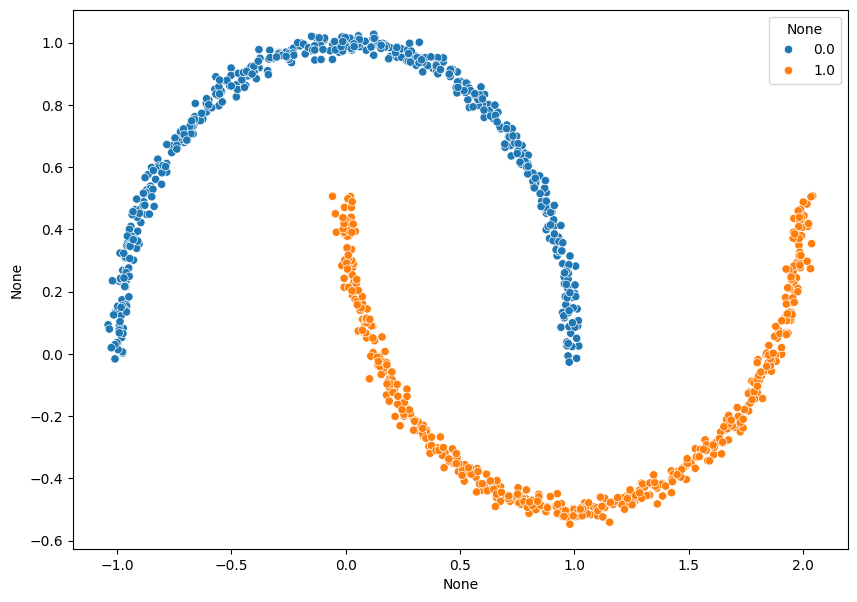

In [30]:
import seaborn as sns
plt.figure(figsize=(10,7))
sns.scatterplot(x=x[:,0],y=x[:,1],hue=y)

In [31]:
class MakeMo(nn.Module):
  def __init__(self):
    super().__init__()
    self.sequential_stack=nn.Sequential(
        nn.Linear(in_features=2,out_features=10),
        nn.ReLU(),
        nn.Linear(in_features=10,out_features=10),
        nn.ReLU(),
        nn.Linear(in_features=10,out_features=1)
    )
  def forward(self,x):
    return self.sequential_stack(x)


In [32]:
model_0=MakeMo()

In [33]:
#Loss fn and optimizer
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.08)

In [34]:
def accuracy_fn(y_true,y_pred):
  correct=torch.eq(y_true,y_pred).sum().item()
  acc=correct/len(y_pred)
  return acc

In [35]:
#Training and testing
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=1000
for epoch in range(epochs):
  model_0.train()
  y_logits=model_0(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
  loss=loss_fn(y_logits,y_train)
  acc=accuracy_fn(y_true=y_train,y_pred=y_pred)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_0.eval()
  with torch.inference_mode():
    test_logits=model_0(x_test).squeeze()
    test_loss=loss_fn(test_logits,y_test)
    test_pred=torch.round(torch.sigmoid(test_logits))
    test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)
  if epoch%10==0:
    print(f"Epoch:{epoch} | Loss:{loss} | Accuracy:{acc} | Test Loss:{test_loss} | Test Accuracy:{test_acc}")

Epoch:0 | Loss:0.6953710913658142 | Accuracy:0.37625 | Test Loss:0.6948277354240417 | Test Accuracy:0.495
Epoch:10 | Loss:0.6847296953201294 | Accuracy:0.71875 | Test Loss:0.6848800778388977 | Test Accuracy:0.71
Epoch:20 | Loss:0.6735506653785706 | Accuracy:0.8175 | Test Loss:0.6746562123298645 | Test Accuracy:0.78
Epoch:30 | Loss:0.6615729331970215 | Accuracy:0.78875 | Test Loss:0.663638710975647 | Test Accuracy:0.775
Epoch:40 | Loss:0.6462562680244446 | Accuracy:0.775 | Test Loss:0.6493762135505676 | Test Accuracy:0.715
Epoch:50 | Loss:0.6257442831993103 | Accuracy:0.76375 | Test Loss:0.6303300857543945 | Test Accuracy:0.695
Epoch:60 | Loss:0.6001673340797424 | Accuracy:0.75625 | Test Loss:0.6066532731056213 | Test Accuracy:0.71
Epoch:70 | Loss:0.5690061450004578 | Accuracy:0.7525 | Test Loss:0.5775379538536072 | Test Accuracy:0.715
Epoch:80 | Loss:0.5341805815696716 | Accuracy:0.76625 | Test Loss:0.544588029384613 | Test Accuracy:0.73
Epoch:90 | Loss:0.4968442916870117 | Accuracy:0.

In [36]:
y_logits.shape,y_train.shape

(torch.Size([800]), torch.Size([800]))

In [15]:
import requests
from pathlib import Path
if Path("helper_functions.py").is_file():
  print("File already exists Skip downloading ")
else:
  print("Downloading helper functions")
  request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open('helper_functions.py','wb') as f:
    f.write(request.content)

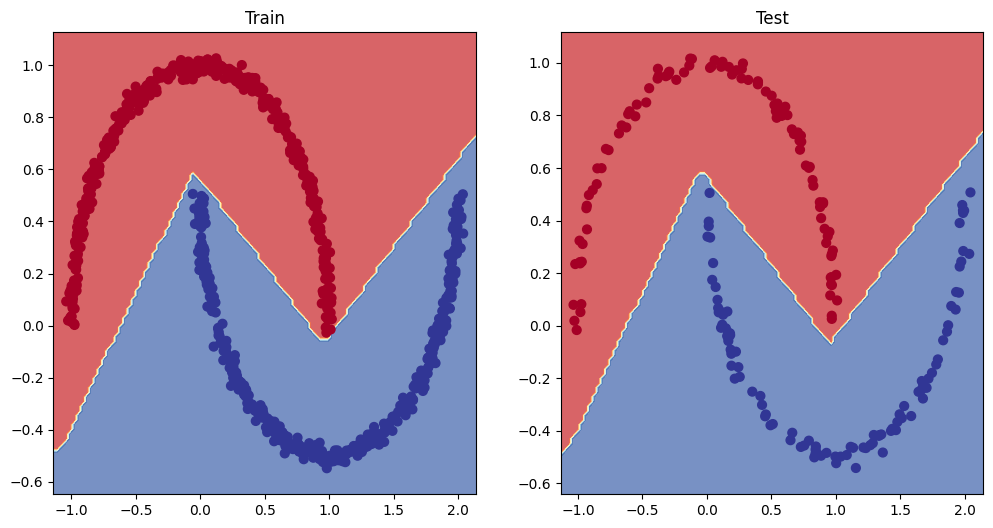

In [39]:
from helper_functions import plot_decision_boundary
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_0,x_train,y_train)
plt.subplot(1,2,2)
plt.title('Test')
plot_decision_boundary(model_0,x_test,y_test)

In [1]:
import torch
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from torch import nn
import matplotlib.pyplot as plt

In [2]:
device='cuda' if torch.cuda.is_available() else 'cuda'

In [3]:
import numpy as np
N = 100 # number of points per class
D = 2 # dimensionality
K = 3 # number of classes
X = np.zeros((N*K,D)) # data matrix (each row = single example)
y = np.zeros(N*K, dtype='uint8') # class labels
for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix] = j

In [4]:
X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.LongTensor)

In [5]:
X=X.to(device)
y=y.to(device)

In [6]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [7]:
X.size()

torch.Size([300, 2])

In [8]:
y.unique()

tensor([0, 1, 2], device='cuda:0')

In [9]:
model_1=nn.Sequential(
    nn.Linear(in_features=2,out_features=10),
    nn.ReLU(),
    nn.Linear(in_features=10,out_features=10),
    nn.ReLU(),
    nn.Linear(in_features=10,out_features=3)
).to(device)

In [10]:
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(params=model_1.parameters(),lr=0.1)

In [12]:
def accuracy_fn(y_true,y_pred):
  correct=torch.eq(y_true,y_pred).sum().item()
  acc=correct/len(y_pred)
  return acc

In [14]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=1000
for epoch in range(epochs):
  model_1.train()
  y_logits=model_1(x_train).squeeze()
  y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)
  loss=loss_fn(y_logits,y_train)
  acc=accuracy_fn(y_true=y_train,y_pred=y_pred)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_1.eval()
  with torch.inference_mode():
    test_logits=model_1(x_test).squeeze()
    test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
    test_loss=loss_fn(test_logits,y_test)
    test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)
  if epoch%10==0:
    print(f"Epoch:{epoch} | Loss:{loss} | Accuracy:{acc} | Test Loss:{test_loss} | Test Accuracy:{test_acc}")

Epoch:0 | Loss:0.029572492465376854 | Accuracy:0.9916666666666667 | Test Loss:0.01446287427097559 | Test Accuracy:1.0
Epoch:10 | Loss:0.02760944701731205 | Accuracy:0.9916666666666667 | Test Loss:0.015494870953261852 | Test Accuracy:1.0
Epoch:20 | Loss:0.02689812146127224 | Accuracy:0.9916666666666667 | Test Loss:0.014955675229430199 | Test Accuracy:1.0
Epoch:30 | Loss:0.026436643674969673 | Accuracy:0.9916666666666667 | Test Loss:0.01393943652510643 | Test Accuracy:1.0
Epoch:40 | Loss:0.02612503059208393 | Accuracy:0.9916666666666667 | Test Loss:0.01311662420630455 | Test Accuracy:1.0
Epoch:50 | Loss:0.025927960872650146 | Accuracy:0.9916666666666667 | Test Loss:0.012472545728087425 | Test Accuracy:1.0
Epoch:60 | Loss:0.025753771886229515 | Accuracy:0.9916666666666667 | Test Loss:0.012009335681796074 | Test Accuracy:1.0
Epoch:70 | Loss:0.02560538612306118 | Accuracy:0.9916666666666667 | Test Loss:0.011635681614279747 | Test Accuracy:1.0
Epoch:80 | Loss:0.02546233870089054 | Accuracy:0

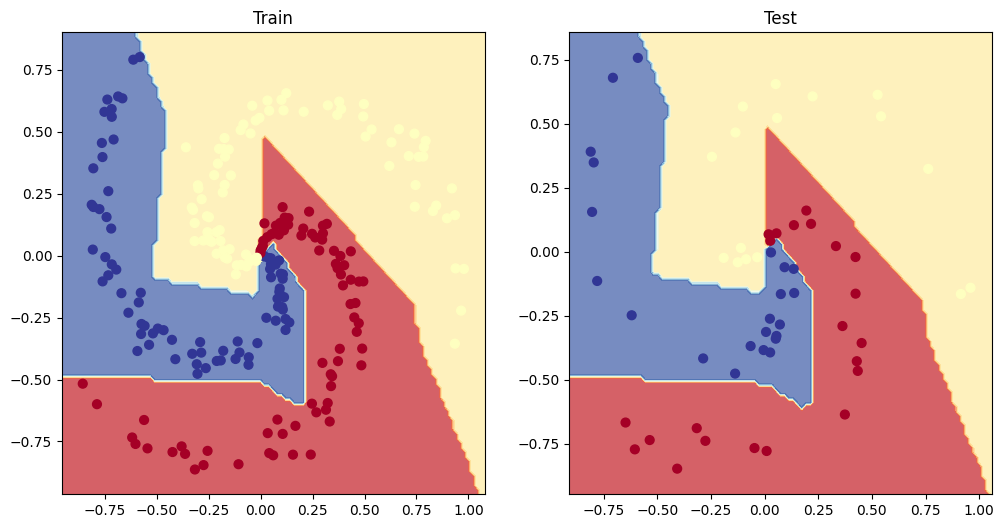

In [16]:
from helper_functions import plot_decision_boundary
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_1,x_train,y_train)
plt.subplot(1,2,2)
plt.title('Test')
plot_decision_boundary(model_1,x_test,y_test)